# 03 · Execution, costs and A-share inventory

Starting empty, T+1 prevents same-day stock round trips. Marked PnL and realized closed-lot outcomes are distinct. The maker model is explicitly simplified and uncalibrated.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from market_microstructure.utils.config import load_config
from market_microstructure.utils.paths import PROJECT_ROOT

ROOT = PROJECT_ROOT
config = load_config()
def table(name):
    return pd.read_csv(ROOT / 'outputs' / 'tables' / f'{name}.csv')
def figure(name):
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f'{name}.png')))
features = pd.read_parquet(ROOT / config['data']['features_path'])
assert set(features.asset) == {'000400.SZ'}
assert features.timestamp.dt.tz is not None


In [2]:
execution = table('execution_summary')
display(execution[['model','mode','gross_pnl','net_pnl','trade_count','residual_inventory_abs','closed_lot_count']])
display(table('pnl_decomposition'))

,model,mode,gross_pnl,net_pnl,trade_count,residual_inventory_abs,closed_lot_count
0,forest,mid,1061.50,1061.500000,10,1000.0,0
1,forest,taker,978.25,889.628374,15,950.0,0
2,forest,maker,1154.00,1104.805600,10,1000.0,0
3,linear,mid,929.00,929.000000,10,1000.0,0
4,linear,taker,918.15,842.284483,13,990.0,0
5,linear,maker,904.90,850.419582,11,920.0,0
6,logistic,mid,916.50,916.500000,10,1000.0,0
7,logistic,taker,861.00,803.406569,10,940.0,0
8,logistic,maker,960.50,910.803660,10,1000.0,0
9,always_long,taker,915.00,857.292755,10,1000.0,0


,model,mode,gross_pnl,realized_gross_alpha,inventory_mark_to_market,spread_cost,total_fees,total_slippage,market_impact,net_pnl,net_pnl_reconciliation_error
0,forest,mid,1061.50,0.0,1061.50,0.0,0.000000,0.000000,0.000000,1061.500000,2.501110e-12
1,forest,taker,978.25,0.0,978.25,12.8,75.186004,0.272549,0.363073,889.628374,3.813057e-10
2,forest,maker,1154.00,0.0,1154.00,-1.0,50.194400,0.000000,0.000000,1104.805600,-3.592504e-11
3,linear,mid,929.00,0.0,929.00,0.0,0.000000,0.000000,0.000000,929.000000,3.069545e-12
4,linear,taker,918.15,0.0,918.15,10.1,65.194816,0.259596,0.311106,842.284483,2.740990e-10
5,linear,maker,904.90,0.0,904.90,-0.7,55.180418,0.000000,0.000000,850.419582,1.188027e-10
6,logistic,mid,916.50,0.0,916.50,0.0,0.000000,0.000000,0.000000,916.500000,3.296918e-12
7,logistic,taker,861.00,0.0,861.00,6.9,50.185057,0.236728,0.271646,803.406569,-7.139533e-11
8,logistic,maker,960.50,0.0,960.50,-0.5,50.196340,0.000000,0.000000,910.803660,-1.384706e-10
9,always_long,taker,915.00,0.0,915.00,7.0,50.196875,0.242862,0.267508,857.292755,-1.223270e-10


## Every-event reconciliation

The cost bridge must equal cash plus marked stock minus initial capital. Same-day sales cannot erase the residual position.

In [3]:
selected = config['model']['type']
ledger = pd.read_parquet(ROOT / f'outputs/backtests/{selected}_taker_events.parquet')
bridge = ledger.gross_pnl - ledger.spread_cost - ledger.fees - ledger.slippage - ledger.impact
np.testing.assert_allclose(ledger.net_pnl, bridge, atol=1e-7)
np.testing.assert_allclose(ledger.equity, ledger.cash + ledger.position * ledger.mid, atol=1e-7)
assert ledger.position.min() >= 0
assert ledger.cash.min() >= 0
closed = pd.read_parquet(ROOT / f'outputs/backtests/{selected}_taker_closed_lots.parquet')
assert closed.empty
print('All events reconcile; closed-trade hit rate is unavailable under this mandate.')

All events reconcile; closed-trade hit rate is unavailable under this mandate.


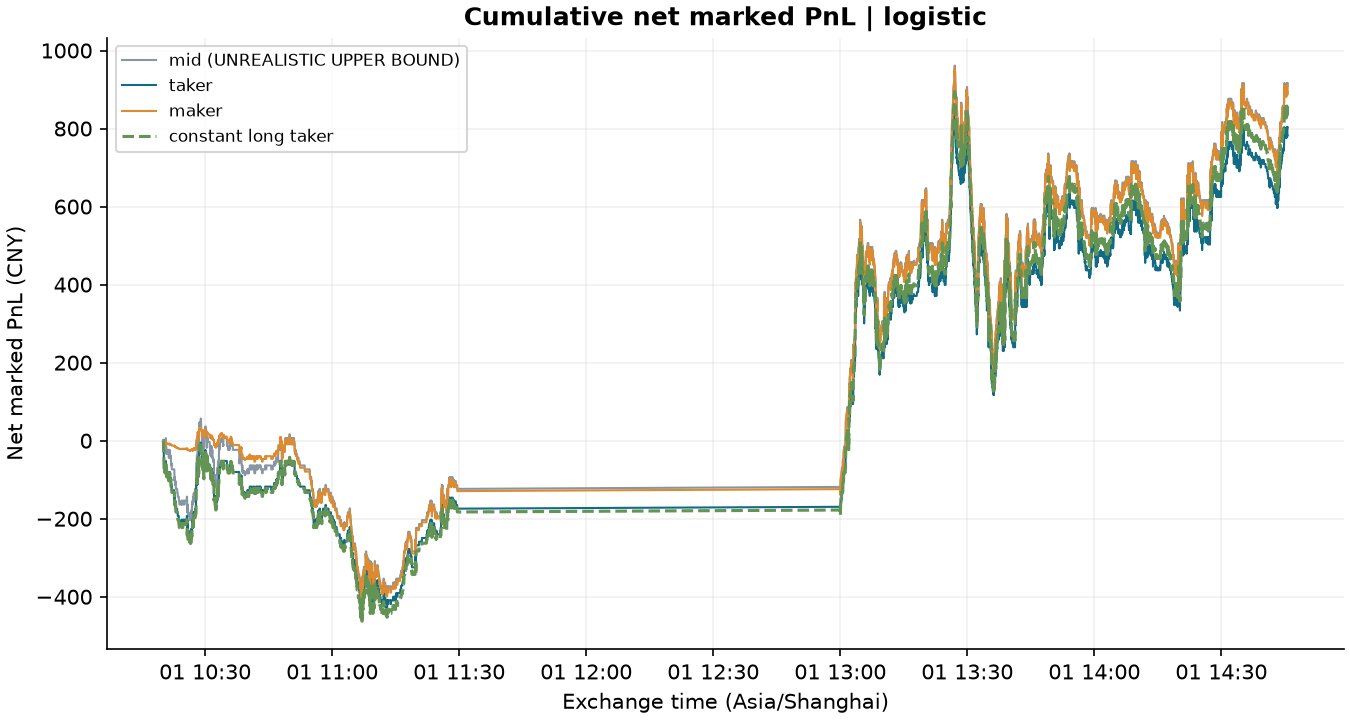

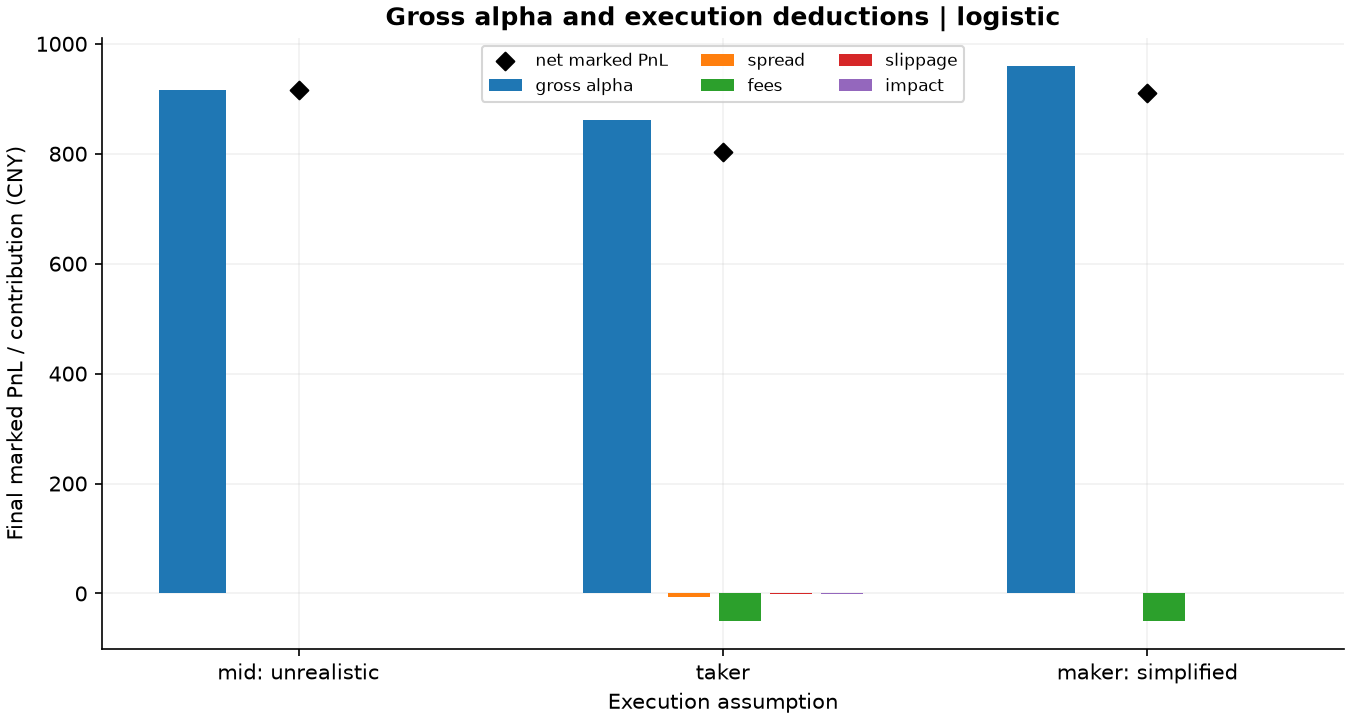

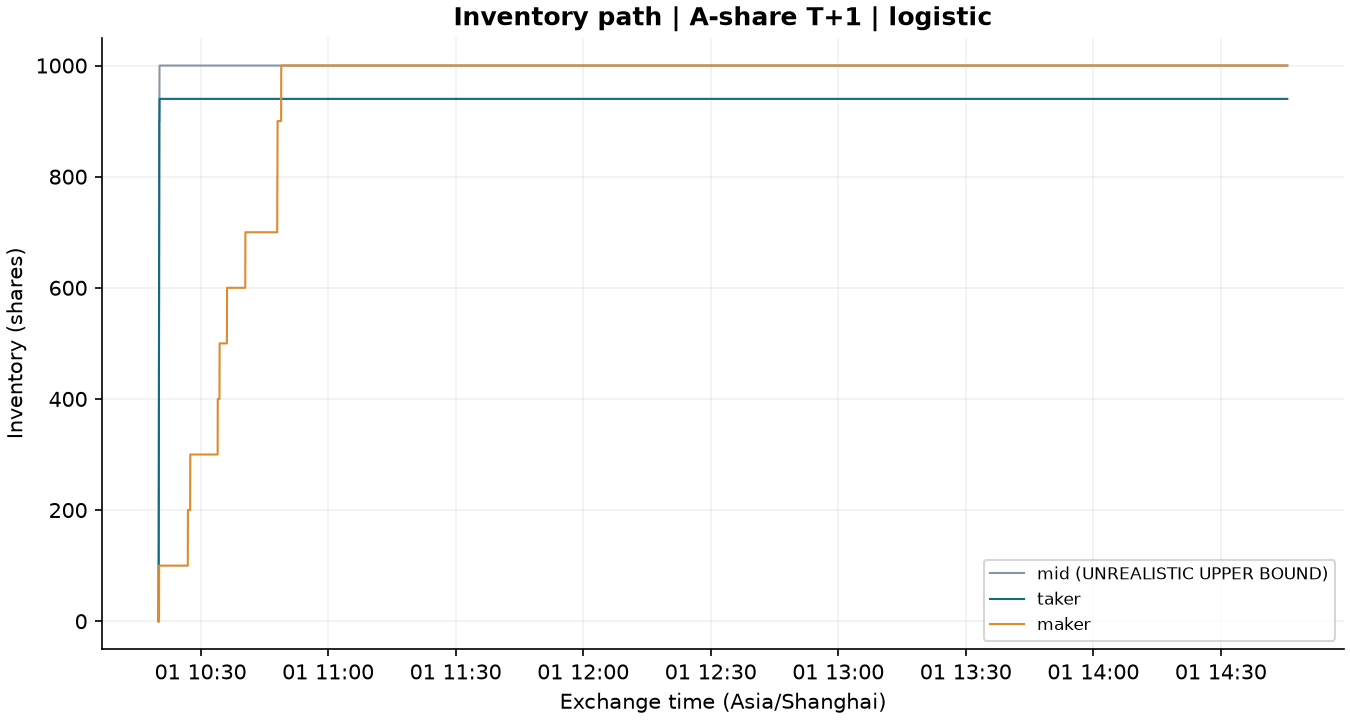

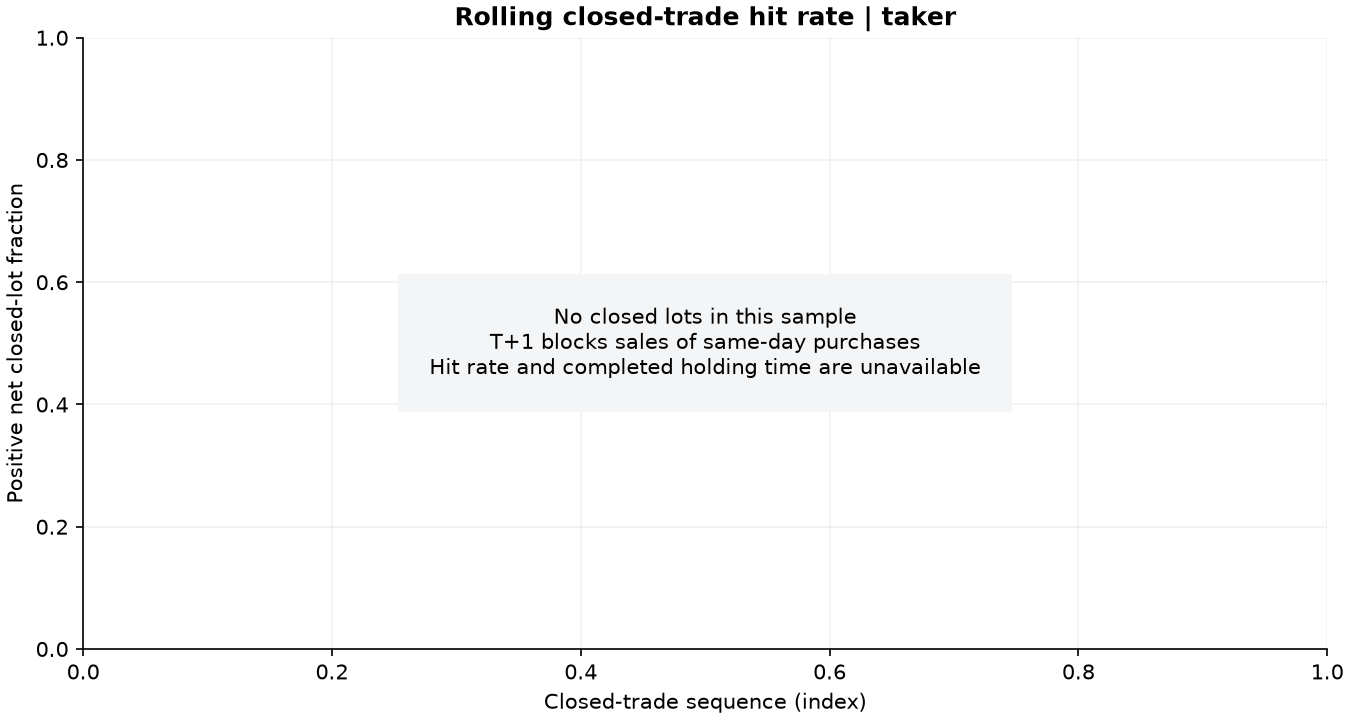

In [4]:
figure('cumulative_net_pnl')
figure('pnl_decomposition')
figure('inventory_path')
figure('rolling_hit_rate')

## Fill and markout assumptions

Future mid labels are used for diagnostics only. Queue proxy, interval aggregation and cancellation timing prevent interpreting these as calibrated exchange fills.

,timestamp,quantity,spread_capture,signed_markout_bps
0,2022-06-01 02:20:15+00:00,100,-1.0,0.000000
1,2022-06-01 02:27:01+00:00,100,1.5,10.248527
2,2022-06-01 02:27:34+00:00,100,1.0,5.117707
3,2022-06-01 02:34:02+00:00,100,-0.5,-5.082592
4,2022-06-01 02:34:28+00:00,100,0.5,0.000000
5,2022-06-01 02:36:13+00:00,100,0.5,-5.082592
6,2022-06-01 02:40:32+00:00,100,0.5,-5.098139
7,2022-06-01 02:48:03+00:00,100,-0.5,-10.175528
8,2022-06-01 02:48:06+00:00,100,-1.0,-2.545825
9,2022-06-01 02:48:58+00:00,100,-0.5,2.541296


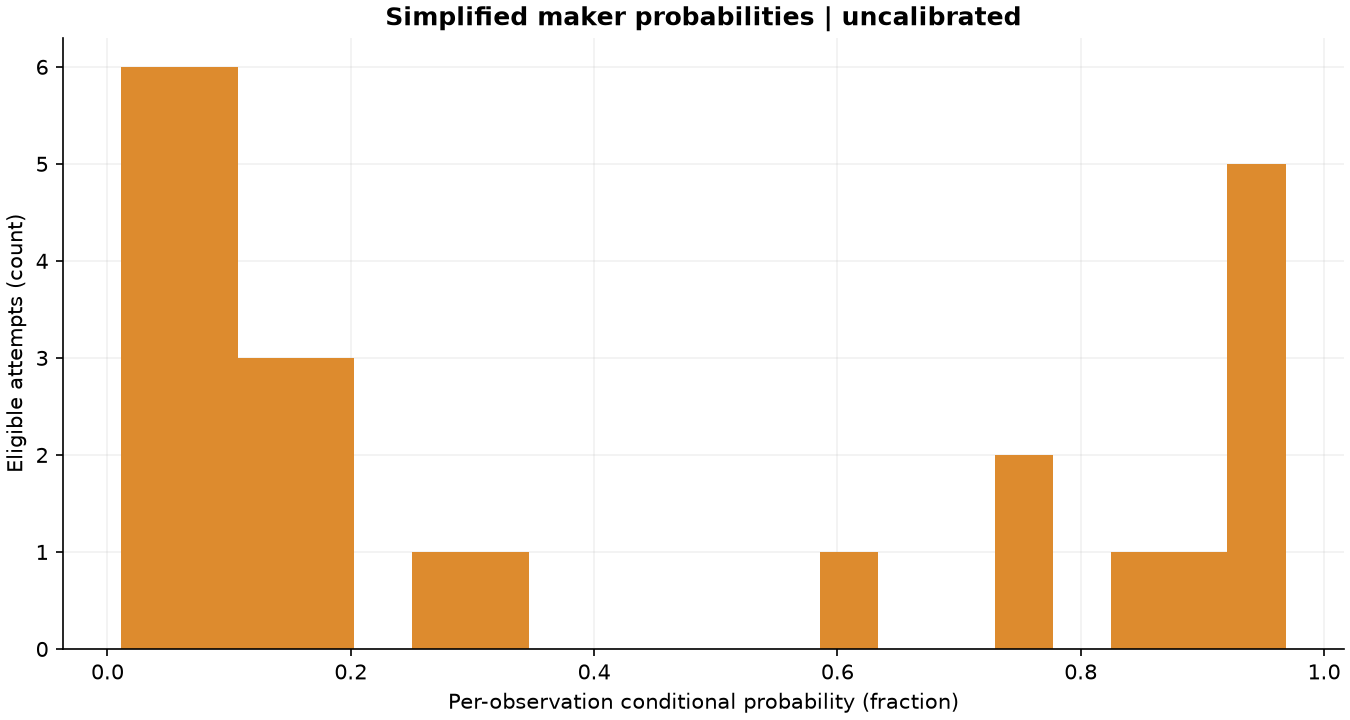

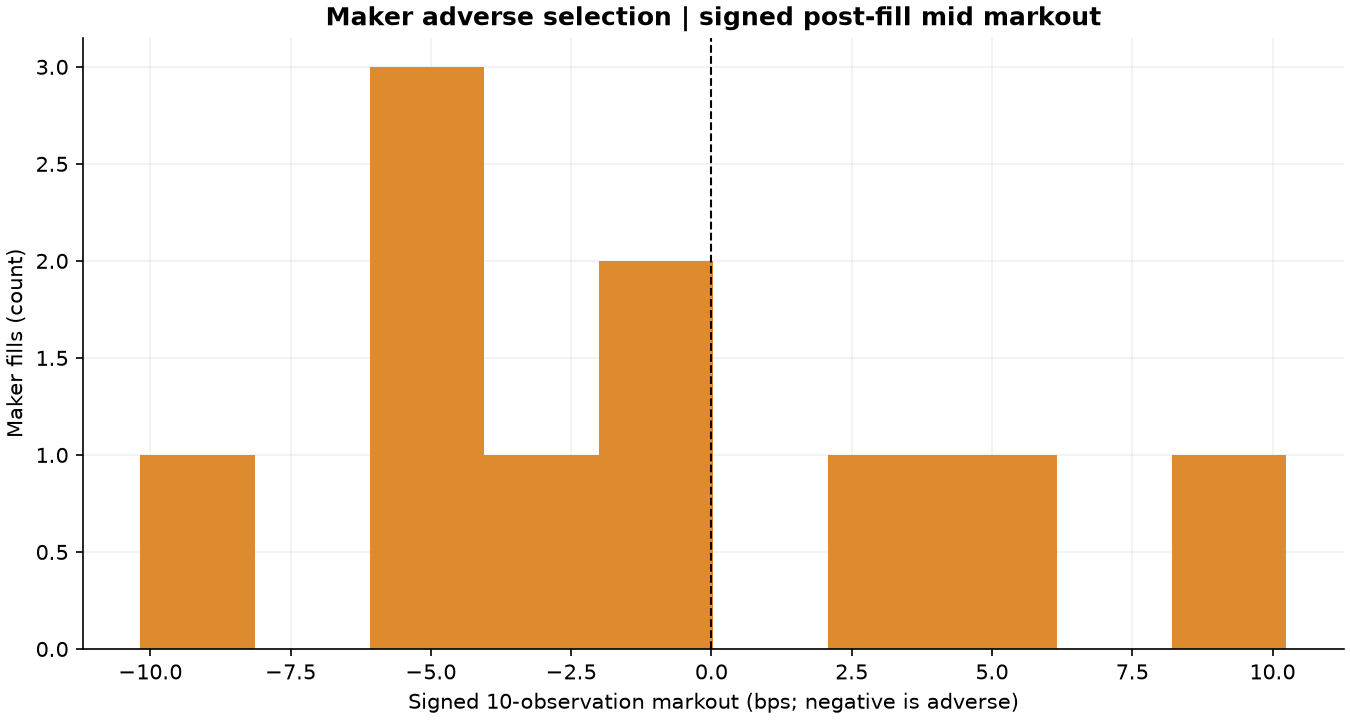

In [5]:
display(table('maker_markouts')[['timestamp','quantity','spread_capture','signed_markout_bps']])
figure('fill_probability')
figure('maker_adverse_selection')

## All predeclared sensitivities

Frozen OOS signals except explicit noise. Scaling the observed path scales its trend too; it is not a new empirical volatility regime.

,scenario,net_pnl,trade_count,residual_inventory_abs,max_drawdown
0,baseline,803.406569,10,940.0,728.500
1,latency_0,857.236439,10,1000.0,775.000
2,latency_1,803.406569,10,940.0,728.500
3,latency_5,848.660532,11,940.0,728.500
4,latency_10,807.139682,11,920.0,713.000
5,spread_1.0,803.406569,10,940.0,728.500
6,spread_1.5,799.956433,10,940.0,728.500
7,spread_2.0,796.506297,10,940.0,728.500
8,fees_1.0,803.406569,10,940.0,728.500
9,fees_2.0,753.406569,10,940.0,728.500


,asset,regime,rows,training_cutoff,signal_ic,prediction_accuracy,net_pnl,spread_cost,fill_count,maker_order_fill_rate,mode
0,000400.SZ,low_volatility,6426,3.862347,0.321193,0.521976,-423.500000,0.000000e+00,10,NaN,mid
1,000400.SZ,high_volatility,4064,3.862347,0.292698,0.534695,1315.000000,0.000000e+00,0,NaN,mid
2,000400.SZ,tight_spread,7401,5.188067,0.312421,0.525639,-721.500000,0.000000e+00,5,NaN,mid
3,000400.SZ,wide_spread,3099,5.188067,0.277688,0.528880,1638.000000,0.000000e+00,5,NaN,mid
4,000400.SZ,low_liquidity,1499,84200.000000,0.141789,0.491605,-920.000000,0.000000e+00,0,NaN,mid
5,000400.SZ,high_liquidity,9001,84200.000000,0.336040,0.532385,1836.500000,0.000000e+00,10,NaN,mid
6,000400.SZ,low_volatility,6426,3.862347,0.321193,0.521976,-456.193431,6.900000e+00,10,NaN,taker
7,000400.SZ,high_volatility,4064,3.862347,0.292698,0.534695,1236.100000,0.000000e+00,0,NaN,taker
8,000400.SZ,tight_spread,7401,5.188067,0.312421,0.525639,-706.416931,2.500000e+00,5,NaN,taker
9,000400.SZ,wide_spread,3099,5.188067,0.277688,0.528880,1509.823499,4.400000e+00,5,NaN,taker


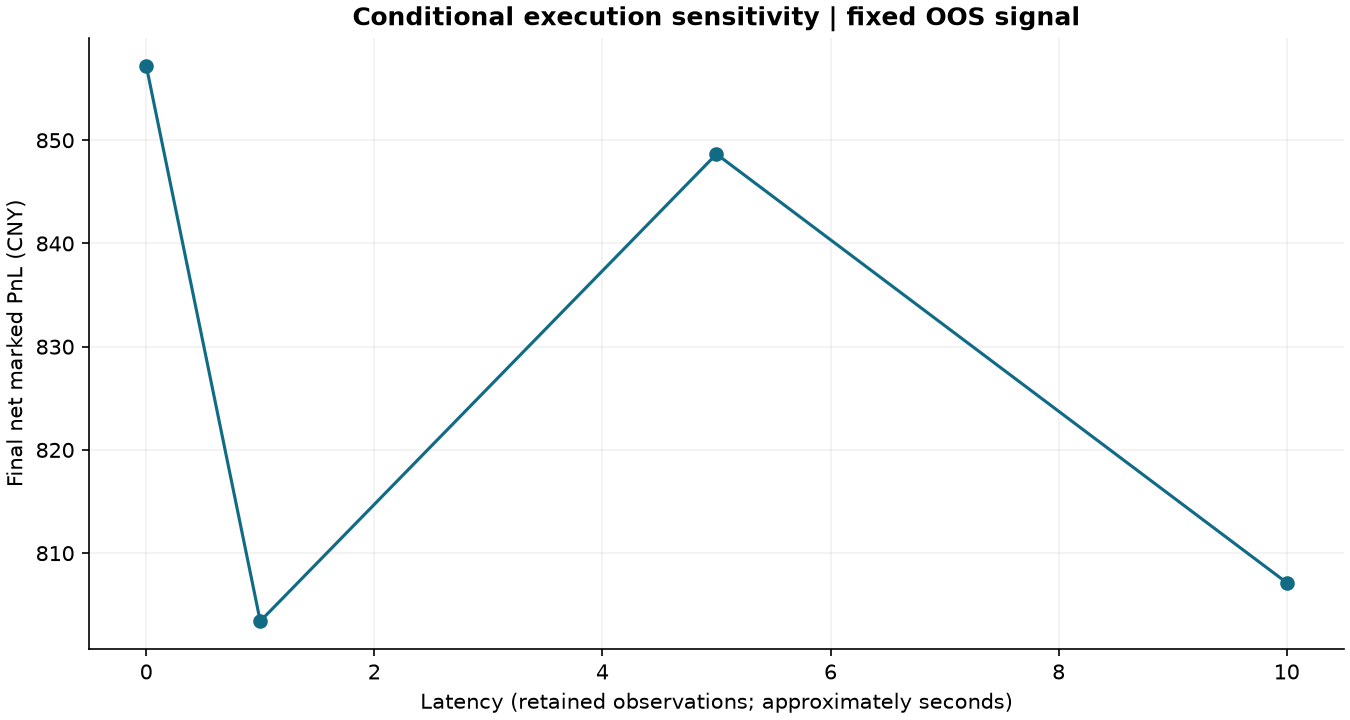

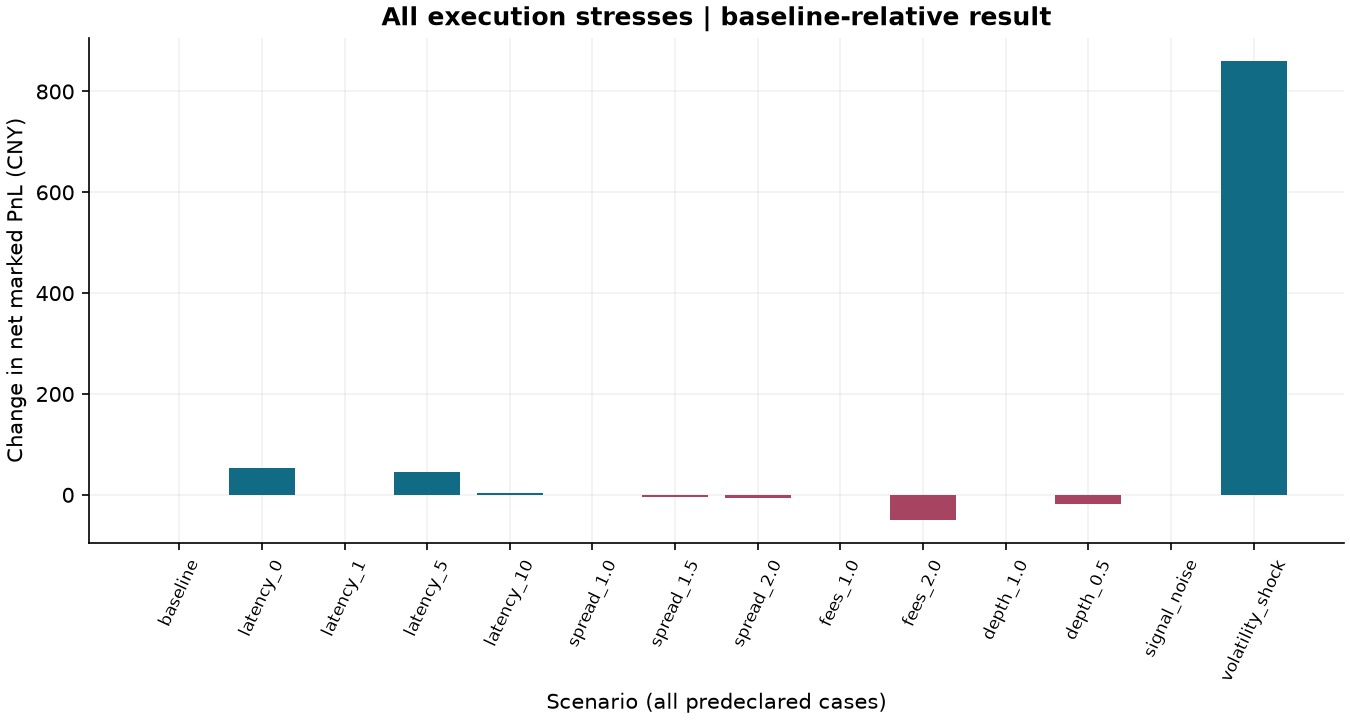

In [6]:
display(table('robustness_summary')[['scenario','net_pnl','trade_count','residual_inventory_abs','max_drawdown']])
display(table('regime_summary'))
figure('pnl_vs_latency')
figure('all_stress_scenarios')